In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, RandomizedSearchCV, cross_validate
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier ,HistGradientBoostingClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    f1_score, accuracy_score
)

RANDOM_STATE = 42
FAST_MODE = True
N_SPLITS = 3 if FAST_MODE else 5
N_ITER = 12 if FAST_MODE else 40
 

In [6]:
data = pd.read_csv("Banking_ml.csv")

print("Shape:", data.shape)
print("\nMissing values per column:\n", data.isnull().sum()[data.isnull().sum() > 0])
print("\nTarget distribution(%):\n",(data["Risk Weighting"].value_counts(normalize=True).sort_index()*100 ) )

Shape: (3000, 32)

Missing values per column:
 Series([], dtype: int64)

Target distribution(%):
 Risk Weighting
1    27.866667
2    40.733333
3    15.333333
4    10.733333
5     5.333333
Name: proportion, dtype: float64


In [ ]:
y = data["Risk Weighting"]
X = data[[
    'Age',
    'Nationality',
    'Fee Structure',
    'Estimated Income',
    'Superannuation Savings',
    'Amount of Credit Cards',
    'Credit Card Balance',
    'Bank Loans',
    'Bank Deposits',
    'Checking Accounts',
    'Saving Accounts',
    'Foreign Currency Account',
    'Business Lending',
    'Properties Owned',
    'Gender',
    'Banking Relationship',
    'Total Assets',
    'Total Debt',
    'Net Financial Position',
    'Deposit to Income Ratio',
    'Loan to Income Ratio',
    'Customer Tenure (Years)'
]]

nominal_cols = ["Gender", "Banking Relationship", "Nationality"]
ordinal_cols = ["Fee Structure"]
ordinal_categories = [["Low", "Mid", "High"]]
numeric_cols = [c for c in X.columns if c not in nominal_cols + ordinal_cols]

print(f"\nNumeric features ({len(numeric_cols)}):", numeric_cols)
print(f"Nominal categorical ({len(nominal_cols)}):", nominal_cols)
print(f"Ordinal categorical ({len(ordinal_cols)}):", ordinal_cols)


Numeric features (18): ['Age', 'Estimated Income', 'Superannuation Savings', 'Amount of Credit Cards', 'Credit Card Balance', 'Bank Loans', 'Bank Deposits', 'Checking Accounts', 'Saving Accounts', 'Foreign Currency Account', 'Business Lending', 'Properties Owned', 'Total Assets', 'Total Debt', 'Net Financial Position', 'Deposit to Income Ratio', 'Loan to Income Ratio', 'Customer Tenure (Years)']
Nominal categorical (3): ['Gender', 'Banking Relationship', 'Nationality']
Ordinal categorical (1): ['Fee Structure']


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("\nTrain class balance:\n", y_train.value_counts(normalize=True).sort_index())
print("Test class balance:\n", y_test.value_counts(normalize=True).sort_index())



Train class balance:
 Risk Weighting
1    0.278750
2    0.407083
3    0.153333
4    0.107500
5    0.053333
Name: proportion, dtype: float64
Test class balance:
 Risk Weighting
1    0.278333
2    0.408333
3    0.153333
4    0.106667
5    0.053333
Name: proportion, dtype: float64


In [9]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numeric_cols),
        ("ord", OrdinalEncoder(categories=ordinal_categories), ordinal_cols),
        ("nom", OneHotEncoder(drop="first", handle_unknown="ignore"), nominal_cols),
    ]
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

In [11]:
logreg_pipe = Pipeline([
    ("prep", preprocessor),
    ("scale", StandardScaler(with_mean=False)),  # sparse-safe after OHE
    ("clf", LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE
    )),
])

logreg_scores = cross_validate(
    logreg_pipe, X_train, y_train, cv=cv,
    scoring=["accuracy", "f1_macro"], n_jobs=-1
)
print("\n--- Logistic Regression (5-fold CV on train) ---")
print("Accuracy: %.3f +/- %.3f" % (logreg_scores["test_accuracy"].mean(), logreg_scores["test_accuracy"].std()))
print("Macro F1: %.3f +/- %.3f" % (logreg_scores["test_f1_macro"].mean(), logreg_scores["test_f1_macro"].std()))



--- Logistic Regression (5-fold CV on train) ---
Accuracy: 0.552 +/- 0.019
Macro F1: 0.438 +/- 0.019


In [12]:
rf_pipe = Pipeline([
    ("prep", preprocessor),
    ("clf", RandomForestClassifier(
        class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1
    )),
])

rf_param_dist = {
    "clf__n_estimators": [200, 300, 400, 500],
    "clf__max_depth": [4, 6, 8, 10, 12, None],
    "clf__min_samples_leaf": [1, 2, 5, 10, 20],
    "clf__min_samples_split": [2, 5, 10, 20],
    "clf__max_features": ["sqrt", "log2", 0.5],
}

rf_search = RandomizedSearchCV(
    rf_pipe, rf_param_dist, n_iter=40, cv=cv,
    scoring="f1_macro", n_jobs=-1, random_state=RANDOM_STATE, verbose=1
)
rf_search.fit(X_train, y_train)
print("\n--- Random Forest (tuned) ---")
print("Best CV macro-F1:", rf_search.best_score_)
print("Best params:", rf_search.best_params_)


Fitting 5 folds for each of 40 candidates, totalling 200 fits

--- Random Forest (tuned) ---
Best CV macro-F1: 0.5137991700740111
Best params: {'clf__n_estimators': 200, 'clf__min_samples_split': 5, 'clf__min_samples_leaf': 2, 'clf__max_features': 0.5, 'clf__max_depth': 12}


In [19]:
gb_pipe = Pipeline([
    ("prep", preprocessor),
    ("clf", HistGradientBoostingClassifier(random_state=RANDOM_STATE)),
])
 
gb_param_dist = {
    "clf__max_iter": [100, 150, 200] if FAST_MODE else [100, 200, 300],
    "clf__learning_rate": [0.03, 0.05, 0.1],
    "clf__max_depth": [3, 5, 7, None],
    "clf__min_samples_leaf": [10, 20, 30],
    "clf__l2_regularization": [0.0, 0.5, 1.0],
}
 
gb_search = RandomizedSearchCV(
    gb_pipe, gb_param_dist, n_iter=N_ITER, cv=cv,
    scoring="f1_macro", n_jobs=-1, random_state=RANDOM_STATE, verbose=1
)
gb_search.fit(X_train, y_train)
print("\n--- Hist Gradient Boosting (tuned) ---")
print("Best CV macro-F1:", gb_search.best_score_)
print("Best params:", gb_search.best_params_)

Fitting 5 folds for each of 12 candidates, totalling 60 fits

--- Hist Gradient Boosting (tuned) ---
Best CV macro-F1: 0.5023500175768858
Best params: {'clf__min_samples_leaf': 30, 'clf__max_iter': 150, 'clf__max_depth': 5, 'clf__learning_rate': 0.05, 'clf__l2_regularization': 1.0}



=== Best model by CV macro-F1: Random Forest (0.514) ===

Test accuracy: 0.6133333333333333
Test macro F1: 0.4911370412721201

Classification report (test set):
               precision    recall  f1-score   support

           1       0.78      0.79      0.78       167
           2       0.67      0.69      0.68       245
           3       0.41      0.49      0.44        92
           4       0.30      0.23      0.26        64
           5       0.41      0.22      0.29        32

    accuracy                           0.61       600
   macro avg       0.51      0.48      0.49       600
weighted avg       0.61      0.61      0.61       600


Saved confusion_matrix.png


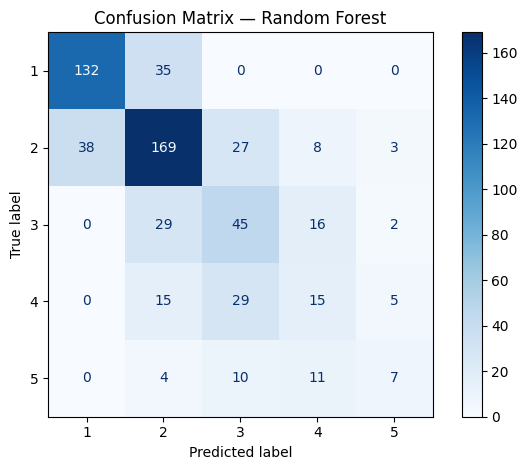

In [20]:
candidates = {
    "Logistic Regression": (logreg_pipe.fit(X_train, y_train), logreg_scores["test_f1_macro"].mean()),
    "Random Forest": (rf_search.best_estimator_, rf_search.best_score_),
    "Gradient Boosting": (gb_search.best_estimator_, gb_search.best_score_),
}

best_name = max(candidates, key=lambda k: candidates[k][1])
best_model, best_cv_score = candidates[best_name]
print(f"\n=== Best model by CV macro-F1: {best_name} ({best_cv_score:.3f}) ===")

y_pred = best_model.predict(X_test)
print("\nTest accuracy:", accuracy_score(y_test, y_pred))
print("Test macro F1:", f1_score(y_test, y_pred, average="macro"))
print("\nClassification report (test set):\n", classification_report(y_test, y_pred, zero_division=0))

cm = confusion_matrix(y_test, y_pred, labels=sorted(y.unique()))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=sorted(y.unique()))
disp.plot(cmap="Blues")
plt.title(f"Confusion Matrix — {best_name}")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
print("\nSaved confusion_matrix.png")


Top 15 feature importances:
 Estimated Income            0.231039
Superannuation Savings      0.133740
Business Lending            0.069991
Foreign Currency Account    0.058228
Credit Card Balance         0.054757
Checking Accounts           0.045291
Customer Tenure (Years)     0.042140
Saving Accounts             0.041677
Total Debt                  0.039844
Bank Loans                  0.037422
Age                         0.036003
Deposit to Income Ratio     0.033276
Net Financial Position      0.031699
Loan to Income Ratio        0.030999
Total Assets                0.030641
dtype: float64
Saved feature_importance.png


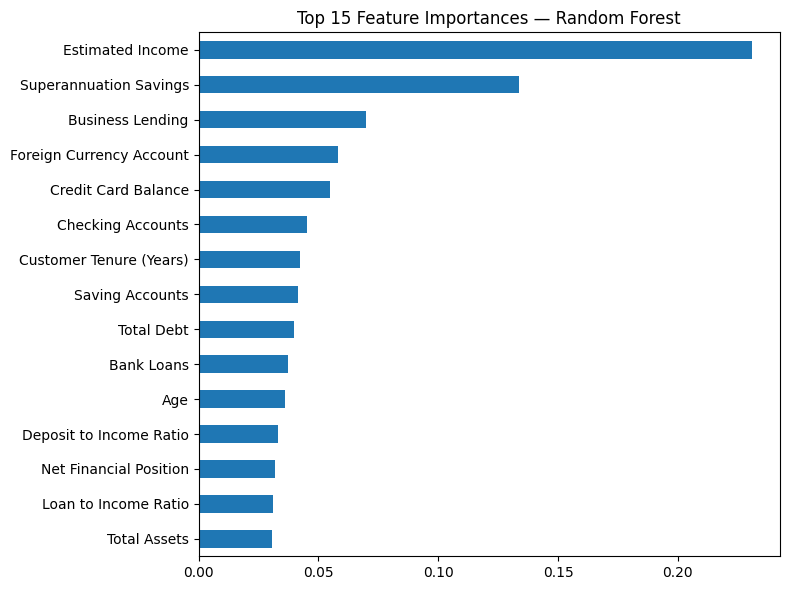

In [21]:
if hasattr(best_model.named_steps["clf"], "feature_importances_"):
    ohe_cols = list(
        best_model.named_steps["prep"]
        .named_transformers_["nom"]
        .get_feature_names_out(nominal_cols)
    )
    all_feature_names = numeric_cols + ordinal_cols + ohe_cols
    importances = pd.Series(
        best_model.named_steps["clf"].feature_importances_, index=all_feature_names
    ).sort_values(ascending=False)
    print("\nTop 15 feature importances:\n", importances.head(15))

    importances.head(15).sort_values().plot(kind="barh", figsize=(8, 6))
    plt.title(f"Top 15 Feature Importances — {best_name}")
    plt.tight_layout()
    plt.savefig("feature_importance.png", dpi=150)
    print("Saved feature_importance.png")

In [ ]:
# joblib.dump(best_model, "risk_weighting_model.pkl")
# print("\nSaved trained pipeline to risk_weighting_model.pkl")
# print("Reload with: model = joblib.load('risk_weighting_model.pkl'); model.predict(new_X)")


Saved trained pipeline to risk_weighting_model.pkl
Reload with: model = joblib.load('risk_weighting_model.pkl'); model.predict(new_X)
